# Ideal neurons → `ideal_neurons.pdf`

What a perfectly retinotopic, relational and proximity neuron look like: one column, one ring
per model (`RING_BY_MODEL`). The retinotopic neuron is shown as its receptive field — a diffuse
blob — rather than chords; the relational ring has only vertical chords (three separations on
each side of fixation), which all drive it equally whatever their position; the proximity ring
has eight 80° chords, which likewise all fire alike, since its rate depends on the separation
alone (preferred separation `SEP_STAR_DEG`). Each ring is coloured on its model's full rate
range, so uniform chords still show how hard they drive the neuron.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.append(str(paths.FIGURES / 'figure_3'))
import common

common.set_style()
import pairs_lib as pairs

OUTPUT = 'ideal_neurons.pdf'
# Each row's phase: the receptive-field direction (retinotopic) or the preferred MIDPOINT AXIS
# (relational, period 180, so 45 and 225 are the same neuron). 0° = east, 90° = north.
# Proximity ignores phase entirely.
PHASE_BY_MODEL = {'retinotopic': 0.0, 'relational': 90.0}
SEP_STAR_DEG = 60.0  # the proximity neuron's preferred separation
RING_SIZE = 1.      # inches: the ring row's axes (ring diameter is ~0.87 of this)
ROW_GAP_IN = 0.25    # INCHES between one row's ring and the next — and the band each row's
                     # title sits in, so it must be tall enough for the text.
TITLE_DY_IN = -0.05    # INCHES to nudge the titles: positive UP, negative DOWN.

# What each row's ring draws.
#   blob=True    — the receptive field as a diffuse bean at the row's phase, bent along the
#                  ring (its shape is set by the BEAN_* knobs below)
#   sep_deg      — chord separation(s); n_chords — evenly spaced midpoints per separation;
#   mids_deg     — explicit chord midpoints instead (0/180 = vertical chords only)
# The retinotopic bean (a Gaussian in polar coordinates, centred at the row's phase):
BEAN_RADIUS = 1.0      # distance of its centre from fixation, in ring radii (1 = on the ring)
BEAN_THICKNESS = 0.15   # SD across the ring (radially), in ring radii
BEAN_WIDTH_DEG = 20.0  # SD along the ring (its width around the arc), in degrees
BEAN_GAIN = 1.5        # intensity: >1 gives a bigger solid-red core and a sharper fade (1 = plain Gaussian)
RING_BY_MODEL = {
    'retinotopic': dict(blob=True, radius=BEAN_RADIUS, sigma=BEAN_THICKNESS,
                        sigma_deg=BEAN_WIDTH_DEG, gain=BEAN_GAIN),
    # Three separations on each side of fixation = 6 vertical chords. 180 would put both
    # sides' chord on the same diameter; these sit at x = ±0.20, ±0.52, ±0.84 of the radius.
    'relational': dict(sep_deg=(157.0, 117.0, 66.0), mids_deg=(0.0, 180.0)),
    'proximity': dict(sep_deg=80.0, n_chords=8),
}
# The red end of the rate colormap: its HSV brightness (`value`, 0-1; lower is darker and less
# pink) and saturation. The shared firing_rate_cmap default is value=0.9.
RED_VALUE = 0.72
RED_SATURATION = 1.0


In [2]:
# Ideal neurons: what a perfectly retinotopic, relational or proximity neuron looks like,
# drawn as a **ring** of 2-object chords coloured by rate (the format of `figure_2/psth.ipynb`).

RING_COLOR = '0.85'
MODEL_COLORS = {'retinotopic': 'tab:blue', 'relational': 'tab:orange', 'proximity': '0.45'}
DISPLAY = {'retinotopic': 'Retinotopic', 'relational': 'Relational', 'proximity': 'Proximity'}

# ── The firing-rate colormap ──────────────────────────────────────────────────
# Copied from `../../figure_2/psth_lib.py`, so the figures that
# share this red do not share an import. `psth.ipynb` draws its rings with
# `firing_rate_cmap()` at these defaults, and these rings are the same object, so they get the
# same colour. Plain `coolwarm` ends at a dark maroon, which is what every per-panel scale
# reaches — that is the dim red this replaces.
COOLWARM = plt.cm.coolwarm     # blue = low firing rate, red = high


def boosted_cmap(cmap=None, value=1.0, saturation=1.0, blend=0.5, n=256, name='boosted'):
    """A colormap whose hot end is lifted **in HSV, at constant hue**.

    `coolwarm` ends at a dark maroon: in HSV that colour is (h 0.97, s 0.98, v 0.71), and it is
    what every per-panel scale reaches, since each panel runs the whole map whatever its rate
    range. Cutting the map short would brighten it only by moving towards the pale centre,
    which desaturates the red — a different colour, not a brighter one. This instead keeps each
    sample's **hue** and interpolates its saturation and value towards `saturation` and
    `value`, so the extreme becomes the same red at full chroma and higher brightness.

    `blend` is the fraction of the map, measured from the hot end, over which that lift ramps
    in. `value=None` returns the colormap unchanged.
    """
    from matplotlib.colors import LinearSegmentedColormap, rgb_to_hsv, hsv_to_rgb
    cmap = COOLWARM if cmap is None else (plt.get_cmap(cmap) if isinstance(cmap, str) else cmap)
    if value is None or blend <= 0:
        return cmap
    t = np.linspace(0.0, 1.0, n)
    rgba = cmap(t)
    hsv = rgb_to_hsv(rgba[:, :3])
    w = np.clip((t - (1.0 - blend)) / blend, 0.0, 1.0)[:, None]      # 0 -> 1 over the top
    target = np.stack([hsv[:, 0], np.full(n, float(saturation)),
                       np.full(n, float(value))], axis=1)            # same hue, new s and v
    rgba[:, :3] = hsv_to_rgb((1.0 - w) * hsv + w * target)
    return LinearSegmentedColormap.from_list(f'{name}_{cmap.name}', rgba)


def skewed_cmap(cmap=None, skew=0.5, n=256, name='skewed'):
    """A colormap whose **neutral colour is moved**, so it is not half blue and half red.

    `skew` is where the pale centre should sit as a fraction of the range: 0.6 puts it 60 % of
    the way from min to max, so 60 % of the range reads blue and red is reserved for the top
    40 %. Implemented by reparameterising position, not colour — every colour of the original
    still appears, in the same order, and the two ends are unchanged.
    """
    from matplotlib.colors import LinearSegmentedColormap
    cmap = COOLWARM if cmap is None else (plt.get_cmap(cmap) if isinstance(cmap, str) else cmap)
    if skew is None or abs(skew - 0.5) < 1e-12:
        return cmap
    if not 0.0 < skew < 1.0:
        raise ValueError(f'skew must be strictly between 0 and 1 (got {skew})')
    t = np.linspace(0.0, 1.0, n)
    src = np.where(t < skew, 0.5 * t / skew, 0.5 + 0.5 * (t - skew) / (1.0 - skew))
    return LinearSegmentedColormap.from_list(f'{name}_{cmap.name}', cmap(src))


def firing_rate_cmap(value=0.9, saturation=1.0, blend=0.5, skew=0.6):
    """The colormap every panel's rate is drawn in — the lift, then the skew.

    The order matters: the lift is defined in the map's own coordinate, so skewing first would
    lift a different amount of red.
    """
    return skewed_cmap(boosted_cmap(value=value, saturation=saturation, blend=blend), skew)


# ── The ideal neurons ─────────────────────────────────────────────────────────
BASELINE, AMPLITUDE = 5.0, 2.0  # the ideal neurons' rate parameters


def ideal_rate(model, t0, t1, phase_deg, sep_star_deg):
    """Noise-free firing rate of an ideal neuron of ``model``.

    ``phase_deg`` is the neuron's receptive-field direction for the retinotopic model, and its
    preferred **axis** for the relational one. The proximity neuron ignores it entirely, which
    is the point of that model: its rate is a function of the **separation** alone, so it has
    no preferred direction and no 1-object receptive field.

    The relational form is written in the pair's sum, ``cos(t0 + t1 - chi)``, whose axis is
    ``(chi + 180)/2``; the conversion happens here so callers only ever name an axis. The
    proximity form is ``cos(separation - sep_star)``, which is monotone in the distance from
    the preferred separation over the whole circle — so it induces exactly the ranking the
    ordinal estimator tests (``-|d - d*|``), and any other tuning with the same peak would
    draw the same picture.
    """
    t0, t1 = np.asarray(t0, float), np.asarray(t1, float)
    if model == 'retinotopic':
        mu = np.radians(phase_deg)
        return BASELINE + AMPLITUDE * (np.cos(t0 - mu) + np.cos(t1 - mu))
    if model == 'relational':
        chi = np.radians(2.0 * phase_deg - 180.0)
        return BASELINE + AMPLITUDE * np.cos(t0 + t1 - chi)
    if model == 'proximity':
        return BASELINE + AMPLITUDE * np.cos(pairs.circ_dist(t0, t1)
                                             - np.radians(sep_star_deg))
    raise ValueError(f'unknown model {model!r}')


# ── Drawing ───────────────────────────────────────────────────────────────────
def rate_range(model):
    """The ideal neuron's full rate range, so every ring of a model shares one colour scale: a
    ring whose chords all fire alike then shows *how* hard they drive it, not a degenerate scale."""
    k = 2.0 if model == 'retinotopic' else 1.0          # the retinotopic rate sums two cosines
    return BASELINE - k * AMPLITUDE, BASELINE + k * AMPLITUDE


def _ring_frame(ax):
    ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color=RING_COLOR, lw=0.9,
                            ls=(0, (2, 2))))
    ax.plot(0, 0, '+', color='0.4', ms=6, mew=1.1)
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect('equal')
    ax.axis('off')


def draw_rf_blob(ax, phase_deg, cmap, sigma=0.15, sigma_deg=30.0, radius=0.85, gain=1.0):
    """A retinotopic neuron's receptive field as a diffuse **bean**: the colormap's hot end,
    fading out as a Gaussian in polar coordinates around the point at ``radius`` in the
    direction ``phase_deg`` -- ``sigma`` wide across the ring (ring radii) and ``sigma_deg``
    along it, so the blob bends with the arc it sits on. ``gain`` multiplies the Gaussian before
    it is capped at full opacity: above 1 it widens the solid core and steepens the fade."""
    # Drawn past the axes (which stop at 1.15) and unclipped, so a bean centred on the ring
    # fades out instead of being cut off at the panel edge.
    lim, n_px = 1.5, 400
    xs = np.linspace(-lim, lim, n_px)
    X, Y = np.meshgrid(xs, xs)
    rho = np.hypot(X, Y)
    dth = np.degrees(pairs.circ_dist(np.arctan2(Y, X), np.radians(phase_deg)))
    img = np.zeros((n_px, n_px, 4))
    img[..., :3] = cmap(1.0)[:3]
    img[..., 3] = np.minimum(1.0, gain * np.exp(-0.5 * ((rho - radius) / sigma) ** 2
                                                - 0.5 * (dth / sigma_deg) ** 2))
    # Crop to where the bean is visible: `bbox_inches='tight'` counts the whole image, so the
    # transparent margin would otherwise pad the saved figure.
    rows = np.flatnonzero(img[..., 3].max(axis=1) > 0.003)
    cols = np.flatnonzero(img[..., 3].max(axis=0) > 0.003)
    img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    ax.imshow(img, extent=(xs[cols[0]], xs[cols[-1]], xs[rows[0]], xs[rows[-1]]),
              origin='lower', interpolation='bilinear', clip_on=False)
    _ring_frame(ax)
    return ax


def draw_ring(ax, model, phase_deg, sep_deg, cmap, sep_star_deg, n_chords=24, mids_deg=None):
    """2-object stimuli as chords coloured by the ideal rate.

    ``sep_deg`` may be one separation or several. One is enough to tell the retinotopic and
    relational neurons apart, and it is what makes their rings comparable — but a proximity
    neuron's rate depends on the separation *alone*, so at a single separation every chord
    carries the same rate and its ring comes out uniform. That is the honest picture of what
    a fixed-separation ring can and cannot show; pass a few separations to give proximity
    something to vary over.

    ``mids_deg`` names the chord midpoints directly (e.g. ``(0, 180)`` for vertical chords
    only), overriding ``n_chords`` evenly spaced ones. Colours are on the model's full rate
    range (:func:`rate_range`), not stretched to the chords drawn.
    """
    seps = np.atleast_1d(np.asarray(sep_deg, float))
    base = (np.radians(np.asarray(mids_deg, float)) if mids_deg is not None
            else np.linspace(0, 2 * np.pi, n_chords, endpoint=False))
    mids = np.concatenate([base] * len(seps))
    half = np.radians(np.repeat(seps, len(base))) / 2
    t0, t1 = mids - half, mids + half
    r = ideal_rate(model, t0, t1, phase_deg, sep_star_deg)
    segs = [[(np.cos(a), np.sin(a)), (np.cos(b), np.sin(b))] for a, b in zip(t0, t1)]
    order = np.argsort(r)
    lc = LineCollection([segs[i] for i in order], cmap=cmap, linewidths=1.8)
    lc.set_array(r[order])
    lc.set_clim(*rate_range(model))
    ax.add_collection(lc)
    _ring_frame(ax)
    return ax


def ideal_figure(phase_by_model, sep_star_deg, ring_by_model, cmap, ring_size=2.3,
                 row_gap_in=0.25, title_dy_in=0.0):
    """One **row per model**, each its 2-object ring with its own title. Returns
    ``(fig, axes)``.

    **Every position here is computed in inches and set by hand**, with no layout engine, so
    every knob below is a real distance rather than a fraction of something that moves. The
    ring axes is ``ring_size`` square and spans [-1.15, 1.15] in data, so the circle's diameter
    is ``ring_size / 1.15``.

    ``phase_by_model``
        Per-row phases. For the **retinotopic** neuron it is a receptive-field *direction*, for
        the **relational** one the preferred *midpoint axis* (period 180, so 45 and 225 are the
        same neuron); the **proximity** neuron ignores it, so it needs no entry.
    ``sep_star_deg``
        The proximity row's preferred separation.
    ``ring_by_model``
        What each row's ring draws. ``{'blob': True, ...}`` draws the receptive field as a
        diffuse blob (:func:`draw_rf_blob`, the other keys being its arguments) instead of
        chords; otherwise a dict of :func:`draw_ring` arguments (``sep_deg``, and ``n_chords``
        or ``mids_deg``).
    ``cmap``
        The rate colormap for every ring.
    ``ring_size``
        Side of the ring axes, in inches.
    ``row_gap_in``
        Vertical space between one row's ring and the next row's — and the band each row's
        title is drawn in, so it also has to be tall enough for the text.
    ``title_dy_in``
        Nudge the titles from their default (sitting just above the ring); positive is **up**.

    The figure is exactly the content, so there is no trailing whitespace for `common.save`'s
    tight bbox to crop.
    """
    models = ('retinotopic', 'relational', 'proximity')
    n = len(models)
    row_pitch = ring_size + row_gap_in
    fig_w, fig_h = ring_size, n * row_pitch
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.set_layout_engine('none')             # nothing may move what is placed below

    title_size = plt.rcParams.get('axes.titlesize', 14)
    axes = []
    for r, m in enumerate(models):
        # Rows run top to bottom; each occupies `row_pitch`, with its title in the gap above.
        ring_y = fig_h - (r + 1) * row_pitch
        ax_ring = fig.add_axes([0.0, ring_y / fig_h, ring_size / fig_w, ring_size / fig_h])
        ph = phase_by_model.get(m, 0.0)       # proximity ignores the phase
        spec = dict(ring_by_model[m])
        if spec.pop('blob', False):
            draw_rf_blob(ax_ring, ph, cmap, **spec)
        else:
            draw_ring(ax_ring, m, ph, cmap=cmap, sep_star_deg=sep_star_deg, **spec)
        fig.text(0.5,
                 (ring_y + ring_size + 0.02 + title_dy_in) / fig_h,
                 DISPLAY[m], color=MODEL_COLORS[m], ha='center', va='bottom',
                 fontsize=title_size)
        axes.append(ax_ring)
    return fig, np.array(axes, dtype=object)


saved ideal_neurons.pdf


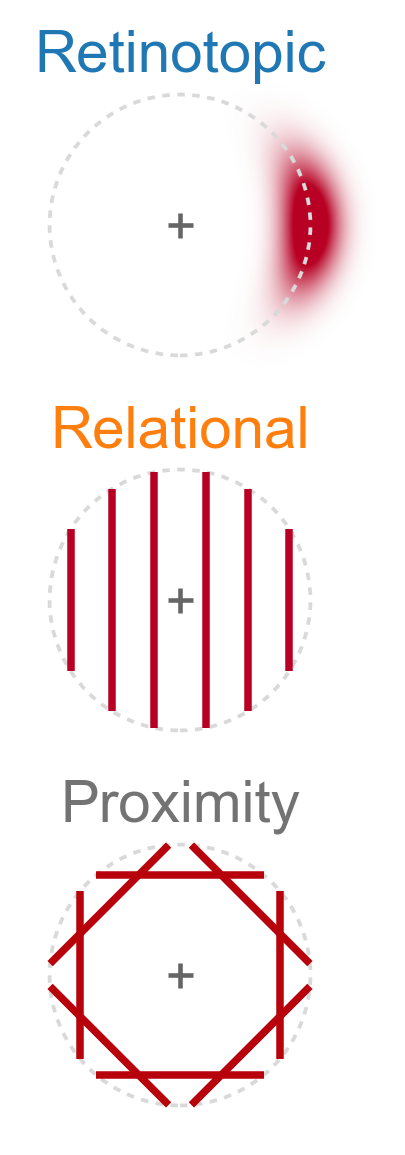

In [3]:
fig, axes = ideal_figure(
    phase_by_model=PHASE_BY_MODEL, sep_star_deg=SEP_STAR_DEG, ring_by_model=RING_BY_MODEL,
    cmap=firing_rate_cmap(value=RED_VALUE, saturation=RED_SATURATION),
    ring_size=RING_SIZE, row_gap_in=ROW_GAP_IN, title_dy_in=TITLE_DY_IN)
common.save(fig, OUTPUT)
plt.show()